# EDA

Exploring the term deposit marketing data before modeling.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats.contingency import association

from src.data.load_data import load_raw_data
from src.utils.config import FIGURES_DIR, TARGET_COL

sns.set_theme(style="whitegrid")

In [3]:
def share_and_rate(groups, subscribed):
    """Return each group's share of customers and subscription rate, in percent."""
    return pd.DataFrame(
        {
            "share": groups.value_counts(normalize=True).mul(100),
            "rate": subscribed.groupby(groups, observed=True).mean().mul(100),
        }
    )


def plot_share_and_rate(ax, summary, title, overall_rate):
    """Plot the share of customers as bars and the subscription rate as a line."""
    labels = summary.index.astype(str)
    ax.bar(labels, summary["share"], color="steelblue")
    ax.set_ylabel("Customers (%)", color="steelblue")
    ax.tick_params(axis="y", colors="steelblue")
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(title)

    rate_ax = ax.twinx()
    rate_ax.plot(labels, summary["rate"], color="darkred", marker="o")
    rate_ax.axhline(overall_rate, color="darkred", linestyle="--", linewidth=1)
    rate_ax.set_ylabel("Subscription rate (%)", color="darkred")
    rate_ax.tick_params(axis="y", colors="darkred")
    rate_ax.set_ylim(bottom=0)
    rate_ax.grid(False)

In [4]:
df = load_raw_data()
df.shape

(40000, 14)

In [5]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,no


What each column means:
- age, job, marital, education: customer background
- default: has credit in default
- balance: average yearly balance in euros
- housing, loan: has a housing loan / personal loan
- contact: how they were contacted
- day, month: date of the last contact
- duration: length of the last call in seconds, known only after the call ends
- campaign: number of calls to this customer during the campaign, including the last one
- y: subscribed to a term deposit

## Data quality check

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        40000 non-null  int64
 1   job        40000 non-null  str  
 2   marital    40000 non-null  str  
 3   education  40000 non-null  str  
 4   default    40000 non-null  str  
 5   balance    40000 non-null  int64
 6   housing    40000 non-null  str  
 7   loan       40000 non-null  str  
 8   contact    40000 non-null  str  
 9   day        40000 non-null  int64
 10  month      40000 non-null  str  
 11  duration   40000 non-null  int64
 12  campaign   40000 non-null  int64
 13  y          40000 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.3 MB


In [7]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
y            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

The dataset has 40,000 rows, with no missing values or duplicate rows. There is no customer ID, so the same customer could still appear more than once.

In [9]:
{col: sorted(df[col].unique()) for col in df.select_dtypes(include="str").columns}

{'job': ['admin',
  'blue-collar',
  'entrepreneur',
  'housemaid',
  'management',
  'retired',
  'self-employed',
  'services',
  'student',
  'technician',
  'unemployed',
  'unknown'],
 'marital': ['divorced', 'married', 'single'],
 'education': ['primary', 'secondary', 'tertiary', 'unknown'],
 'default': ['no', 'yes'],
 'housing': ['no', 'yes'],
 'loan': ['no', 'yes'],
 'contact': ['cellular', 'telephone', 'unknown'],
 'month': ['apr',
  'aug',
  'dec',
  'feb',
  'jan',
  'jul',
  'jun',
  'mar',
  'may',
  'nov',
  'oct'],
 'y': ['no', 'yes']}

In [10]:
unknown_counts = (df == "unknown").sum()

unknown_summary = pd.DataFrame(
    {
        "count": unknown_counts,
        "percent": (unknown_counts / len(df) * 100).round(1),
    }
)

unknown_summary[unknown_summary["count"] > 0]

,count,percent
job,235,0.6
education,1531,3.8
contact,12765,31.9


"Unknown" appears in contact (31.9% of customers), education (3.8%), and job (0.6%). It is kept as its own category. Dropping these rows would remove almost a third of the data, and filling in the most common value would hide any difference between these customers and the rest.

In [11]:
months = [
    "jan",
    "feb",
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec",
]

df["month"].value_counts().reindex(months, fill_value=0)

month
jan     1176
feb     2296
mar      258
apr     2718
may    13532
jun     4734
jul     6380
aug     5215
sep        0
oct       80
nov     3598
dec       13
Name: count, dtype: int64

There are no September records. December has only 13 customers, October 80, and March 258, compared with 13,532 in May, the busiest month. Rates for these three months rest on a few customers, especially December.

In [12]:
df.describe()

,age,balance,day,duration,campaign
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,40.544600,1274.277550,16.017225,254.824300,2.882175
std,9.641776,2903.769716,8.278127,259.366498,3.239051
min,19.000000,-8019.000000,1.000000,0.000000,1.000000
25%,33.000000,54.000000,8.000000,100.000000,1.000000
50%,39.000000,407.000000,17.000000,175.000000,2.000000
75%,48.000000,1319.000000,21.000000,313.000000,3.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000


In [13]:
negative_balance = df["balance"] < 0

pd.DataFrame(
    {
        "count": negative_balance.value_counts(),
        "percent": negative_balance.value_counts(normalize=True).mul(100).round(1),
    }
)

,count,percent
balance,,
False,36269,90.7
True,3731,9.3


- Ages range from 19 to 95, and half of customers are between 33 and 48. No age is impossible.
- The day of last contact ranges from 1 to 31, which are all valid days of a month.
- Calls per customer range from 1 to 63, with a 75th percentile of 3 calls.
- Duration ranges from 0 to 4,918 seconds (about 82 minutes), with a 75th percentile of 313 seconds (about 5 minutes). The zero-second calls are checked below.
- Balance ranges from -8,019 to 102,127 euros, with a 75th percentile of 1,319 euros. About 1 in 11 customers (9.3%) has a negative balance, meaning the account was overdrawn on average over the year.

These maximums are far above the 75th percentiles but possible, so they are kept.

In [14]:
df.skew(numeric_only=True).round(1)

age         0.4
balance     8.3
day         0.1
duration    3.2
campaign    4.7
dtype: float64

Balance (8.3), duration (3.2), and campaign (4.7) have a skewness above 1. Age (0.4) and day (0.1) are below 0.5, so they are close to symmetric. In the three skewed columns, the mean is well above the median (balance 1,274 vs. 407 euros, duration 255 vs. 175 seconds, campaign 2.88 vs. 2 calls), so the median is a better summary than the mean for them.

In [15]:
df.loc[df["duration"] == 0, ["duration", TARGET_COL]]

,duration,y
6424,0,no
22937,0,no
36425,0,no


Three calls have a duration of 0 seconds, and none of the three customers subscribed. They are probably unanswered calls, and three rows are too few to affect the results, so they are kept.

## Target

In [16]:
pd.DataFrame(
    {
        "count": df[TARGET_COL].value_counts(),
        "percent": df[TARGET_COL].value_counts(normalize=True).mul(100).round(1),
    }
)

,count,percent
y,,
no,37104,92.8
yes,2896,7.2


92.8% of customers did not subscribe and 7.2% did, about 13 "no" for every "yes". A model that always predicts "no" would score 92.8% accuracy, above the 81% target, without finding a single subscriber. So accuracy alone cannot judge the models.

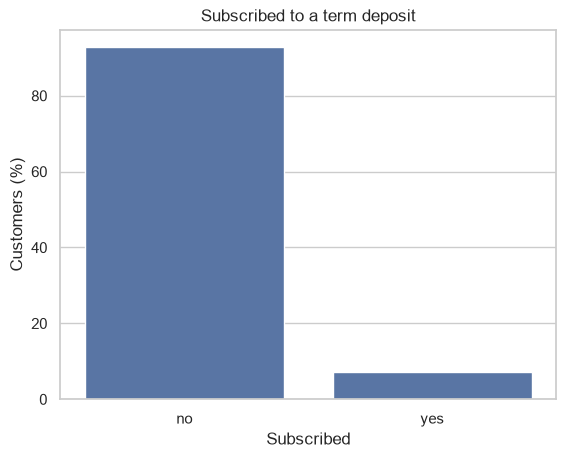

In [17]:
sns.countplot(x=TARGET_COL, data=df, order=["no", "yes"], stat="percent")
plt.title("Subscribed to a term deposit")
plt.xlabel("Subscribed")
plt.ylabel("Customers (%)")
plt.savefig(FIGURES_DIR / "target_balance.png", bbox_inches="tight")
plt.show()

The models are compared on PR-AUC, recall (share of subscribers found), and precision (share of calls that reach a subscriber). Every split and CV fold is stratified so it keeps the 7.2% subscription rate.

In [18]:
subscribed = df[TARGET_COL].eq("yes")
overall_rate = subscribed.mean() * 100

## Numeric features

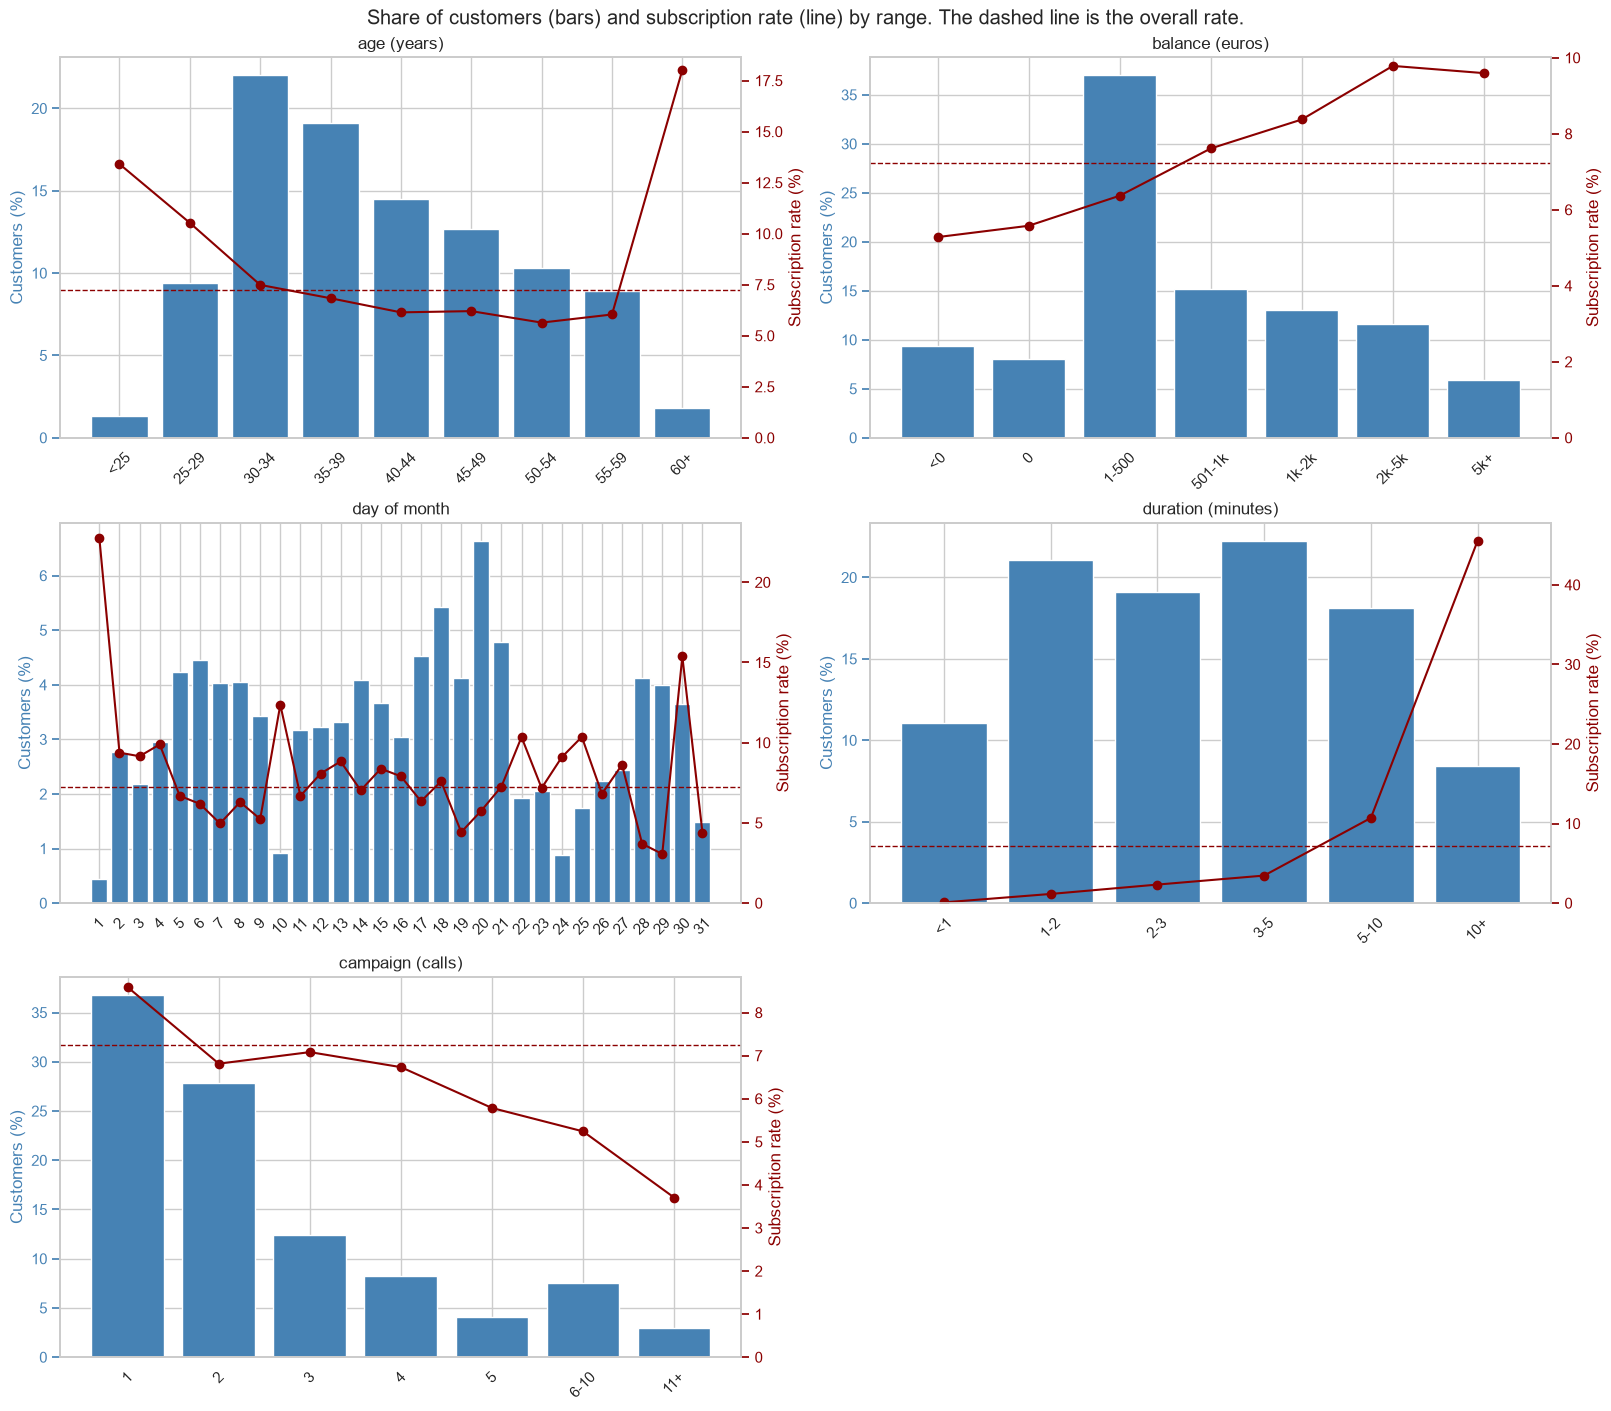

In [19]:
numeric_cols = df.select_dtypes(include="number").columns

numeric_bins = {
    "age": (
        [0, 25, 30, 35, 40, 45, 50, 55, 60, np.inf],
        ["<25", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60+"],
    ),
    "balance": (
        [-np.inf, 0, 1, 501, 1001, 2001, 5001, np.inf],
        ["<0", "0", "1-500", "501-1k", "1k-2k", "2k-5k", "5k+"],
    ),
    "duration": (
        [0, 60, 120, 180, 300, 600, np.inf],
        ["<1", "1-2", "2-3", "3-5", "5-10", "10+"],
    ),
    "campaign": (
        [1, 2, 3, 4, 5, 6, 11, np.inf],
        ["1", "2", "3", "4", "5", "6-10", "11+"],
    ),
}

titles = {
    "age": "age (years)",
    "balance": "balance (euros)",
    "day": "day of month",
    "duration": "duration (minutes)",
    "campaign": "campaign (calls)",
}

binned_rates = {}
fig, axs = plt.subplots(3, 2, figsize=(16, 14), layout="constrained")
for ax, col in zip(axs.flat, numeric_cols, strict=False):
    if col in numeric_bins:
        edges, labels = numeric_bins[col]
        groups = pd.cut(df[col], bins=edges, labels=labels, right=False)
    else:
        groups = df[col]
    summary = share_and_rate(groups, subscribed).sort_index()
    binned_rates[col] = summary.round(1)
    plot_share_and_rate(ax, summary, titles[col], overall_rate)
axs.flat[-1].set_visible(False)
fig.suptitle(
    "Share of customers (bars) and subscription rate (line) by range. "
    "The dashed line is the overall rate."
)
fig.savefig(FIGURES_DIR / "numeric_features.png", bbox_inches="tight")
plt.show()

In [20]:
binned_rates

{'age':        share  rate
 age               
 <25      1.3  13.4
 25-29    9.4  10.5
 30-34   22.0   7.5
 35-39   19.1   6.8
 40-44   14.5   6.1
 45-49   12.7   6.2
 50-54   10.3   5.6
 55-59    8.9   6.0
 60+      1.8  18.0,
 'balance':          share  rate
 balance             
 <0         9.3   5.3
 0          8.0   5.6
 1-500     37.0   6.4
 501-1k    15.1   7.6
 1k-2k     13.0   8.4
 2k-5k     11.6   9.8
 5k+        5.9   9.6,
 'day':      share  rate
 day             
 1      0.4  22.7
 2      2.8   9.4
 3      2.2   9.2
 4      3.0   9.9
 5      4.2   6.7
 6      4.4   6.2
 7      4.0   5.0
 8      4.0   6.3
 9      3.4   5.2
 10     0.9  12.4
 11     3.2   6.7
 12     3.2   8.1
 13     3.3   8.8
 14     4.1   7.0
 15     3.7   8.4
 16     3.0   7.9
 17     4.5   6.3
 18     5.4   7.6
 19     4.1   4.4
 20     6.6   5.8
 21     4.8   7.3
 22     1.9  10.3
 23     2.1   7.2
 24     0.9   9.1
 25     1.7  10.4
 26     2.2   6.8
 27     2.4   8.6
 28     4.1   3.7
 29     4.0   3

In [21]:
age_split = pd.cut(
    df["age"],
    bins=[0, 60, 61, np.inf],
    labels=["under 60", "60", "over 60"],
    right=False,
)

pd.DataFrame(
    {
        "customers": age_split.value_counts(),
        "rate": subscribed.groupby(age_split, observed=True).mean().mul(100).round(1),
    }
).sort_index()

,customers,rate
age,,
under 60,39273,7.0
60,493,8.1
over 60,234,38.9


In [22]:
day_30 = df["day"] == 30
day_30_months = df.loc[day_30, "month"]

pd.DataFrame(
    {
        "customers": day_30_months.value_counts(),
        "rate": subscribed[day_30].groupby(day_30_months).mean().mul(100).round(1),
    }
).sort_values("customers", ascending=False)

,customers,rate
month,,
may,441,6.1
jul,393,7.6
apr,315,46.0
jan,248,4.8
jun,36,0.0
mar,17,29.4
oct,7,71.4


- The subscription rate is highest at both ends of the age range, 13.4% for customers under 25 (1.3% of customers) and 18.0% for 60+ (1.8%). Every group from 35 to 59 is below the overall 7.2%. Within 60+, the 234 customers over 60 subscribe at 38.9%, and the 493 customers aged exactly 60 subscribe at 8.1%.
- The subscription rate rises with balance, from 5.3% for negative balances to 9.8% for 2k-5k, and levels off above 2,000 euros (9.6% for 5k+). Every group up to 500 euros is below the overall rate, and those groups make up about 54% of customers.
- The day line jumps more than any other panel, and some of the biggest jumps are on days with few customers (22.7% on day 1, which has 0.4% of customers). Day 30 has 3.6% of customers and a 15.4% rate, mostly from April 30 (315 customers, 46.0% subscribed). In May, July, and January, the other months with the most day-30 customers, the day-30 rate is between 4.8% and 7.6%. So the high day-30 rate comes from a single date, April 30.
- Duration has the steepest rise, from 0.1% for calls under 1 minute to 45.5% for calls of 10 minutes or more. Every group under 5 minutes is below the overall rate, and those groups make up about 73% of customers.
- The subscription rate falls as the number of calls goes up, from 8.6% for customers called once (36.8% of customers, the only group above the overall rate) to 3.7% for 11 or more calls (3.0% of customers). A customer who subscribed early was probably not called again, so this chart does not show that extra calls lower the chance of subscribing.

In [23]:
retired_age = df.loc[df["job"] == "retired", "age"]
retired_age.describe()

count    1437.000000
mean       57.185108
std         7.064307
min        24.000000
25%        55.000000
50%        58.000000
75%        59.000000
max        95.000000
Name: age, dtype: float64

In [24]:
(retired_age > 60).sum()

np.int64(163)

Only 234 customers (0.6%) are over 60. Even among the 1,437 retired customers, the median age is 58, and 163 of them (11.3%) are over 60, so the campaign mostly called customers aged 60 or younger. The model has few examples of customers over 60, the age group with the highest subscription rate (38.9%).

In [25]:
df.groupby(TARGET_COL)[numeric_cols].median()

,age,balance,day,duration,campaign
y,,,,,
no,39.0,395.0,17.0,164.0,2.0
yes,37.0,620.0,16.0,629.0,2.0


- The median last call lasted 629 seconds (about 10.5 minutes) for subscribers, almost 4 times the 164 seconds (about 2.7 minutes) for non-subscribers.
- The median balance is 225 euros higher for subscribers (620 vs. 395 euros), which fits the rising balance line.
- The medians for age (37 vs. 39), calls (2 each), and day (16 vs. 17) are close for the two groups. The age and call medians hide the high rates at both ends of the age range and the falling rate as calls go up.

## Categorical features

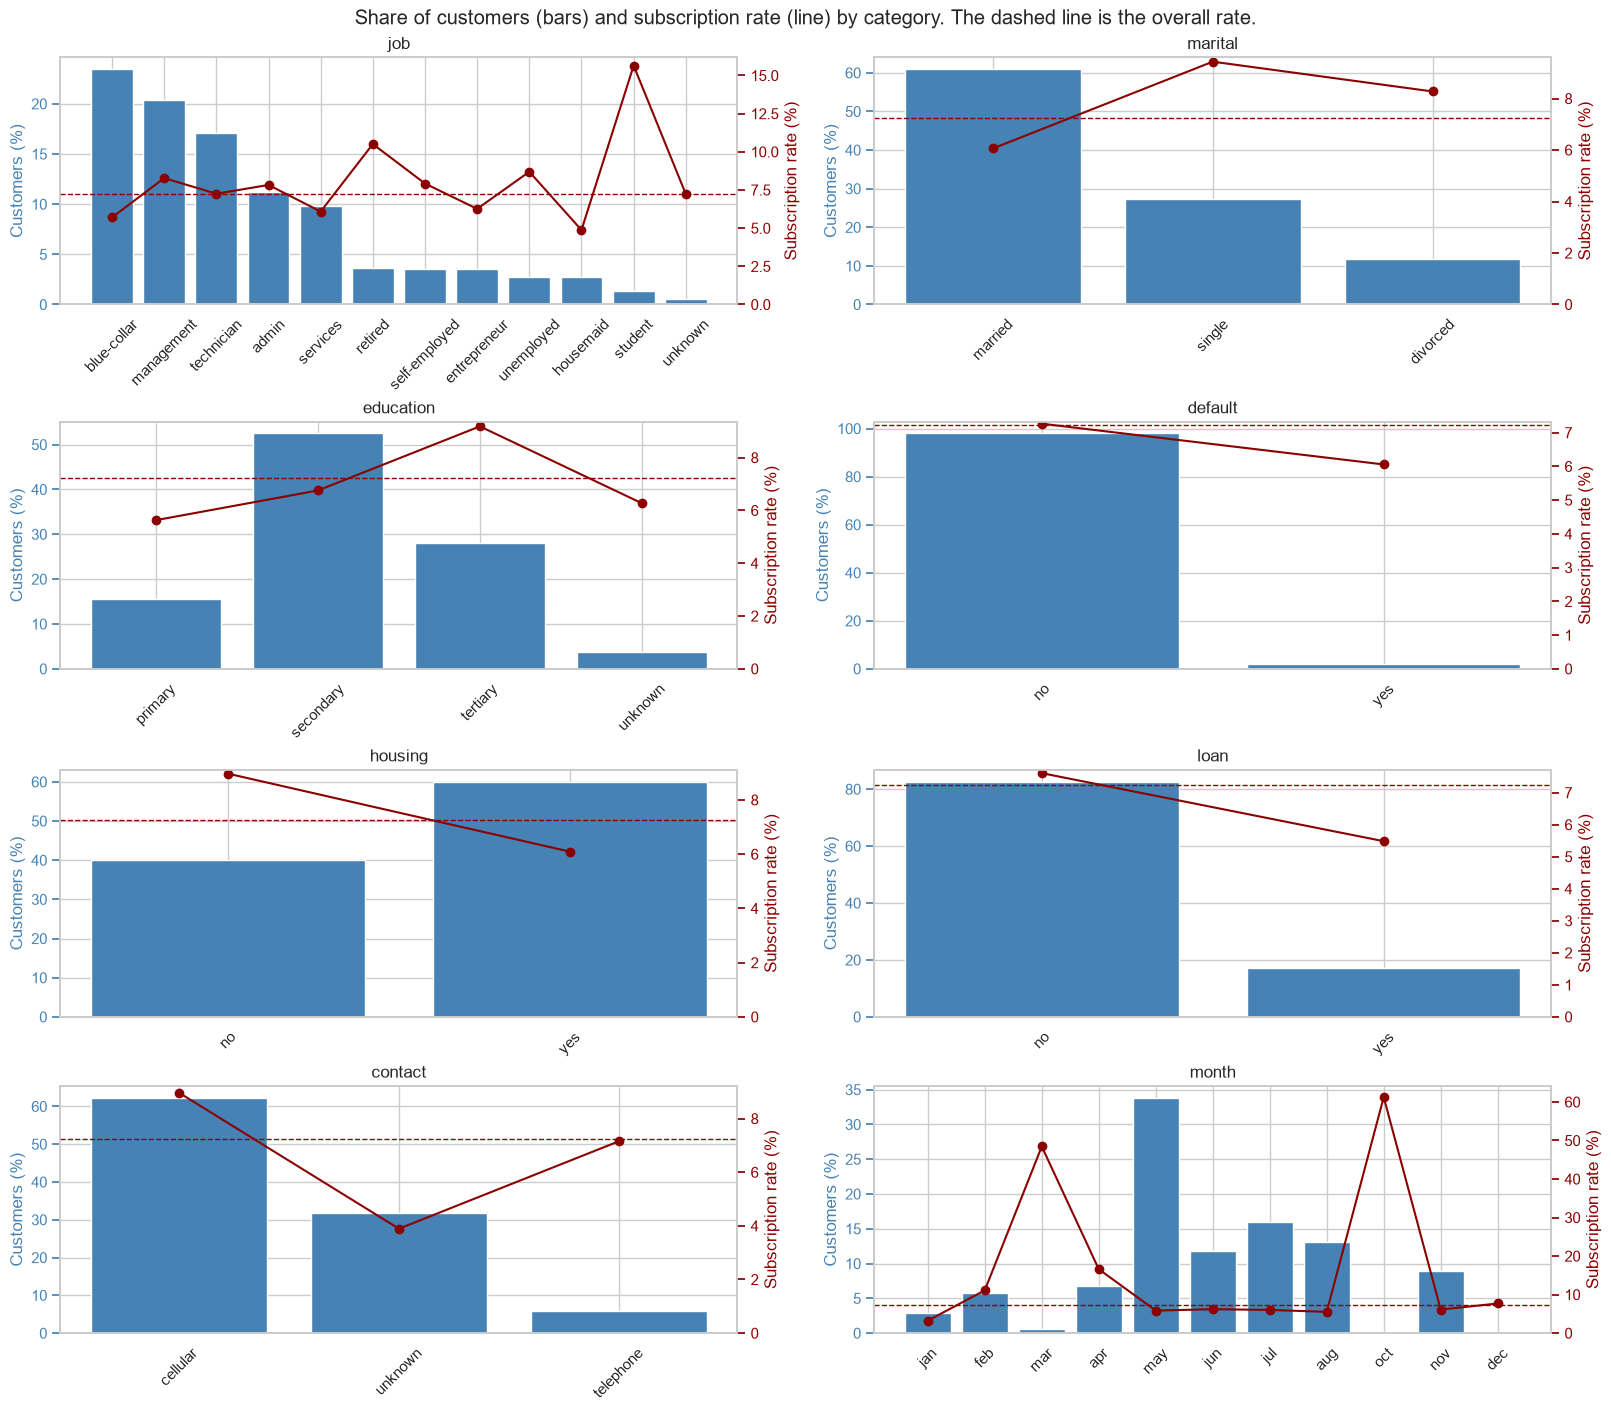

In [26]:
categorical_cols = df.select_dtypes(include="str").columns.drop(TARGET_COL)
category_orders = {
    "education": ["primary", "secondary", "tertiary", "unknown"],
    "default": ["no", "yes"],
    "housing": ["no", "yes"],
    "loan": ["no", "yes"],
    "month": months,
}

category_rates = {}
fig, axs = plt.subplots(4, 2, figsize=(16, 14), layout="constrained")
for ax, col in zip(axs.flat, categorical_cols, strict=True):
    summary = share_and_rate(df[col], subscribed)
    if col in category_orders:
        summary = summary.reindex(category_orders[col]).dropna()
    else:
        summary = summary.sort_values("share", ascending=False)
    category_rates[col] = summary.round(1)
    plot_share_and_rate(ax, summary, col, overall_rate)
fig.suptitle(
    "Share of customers (bars) and subscription rate (line) by category. "
    "The dashed line is the overall rate."
)
fig.savefig(FIGURES_DIR / "categorical_features.png", bbox_inches="tight")
plt.show()

In [27]:
category_rates

{'job':                share  rate
 job                       
 blue-collar     23.5   5.7
 management      20.4   8.3
 technician      17.1   7.3
 admin           11.2   7.8
 services         9.8   6.1
 retired          3.6  10.5
 self-employed    3.5   7.9
 entrepreneur     3.5   6.3
 unemployed       2.8   8.7
 housemaid        2.7   4.9
 student          1.3  15.6
 unknown          0.6   7.2,
 'marital':           share  rate
 marital              
 married    61.0   6.1
 single     27.2   9.4
 divorced   11.8   8.3,
 'education':            share  rate
 education             
 primary     15.7   5.6
 secondary   52.5   6.8
 tertiary    28.0   9.2
 unknown      3.8   6.3,
 'default':          share  rate
 default             
 no        98.0   7.3
 yes        2.0   6.1,
 'housing':          share  rate
 housing             
 no        39.9   9.0
 yes       60.1   6.1,
 'loan':       share  rate
 loan             
 no     82.7   7.6
 yes    17.3   5.5,
 'contact':            share  

- The five busiest months (May, June, July, August, and November) make up about 84% of customers, and all five are below the overall rate, between 5.5% and 6.2%. The highest rates are in October (61.3%), March (48.4%), and April (16.6%). October and March have only 80 and 258 customers, so their exact rates are uncertain, but both are still far above the overall 7.2%. January is the lowest at 3.2%.
- Customers with an unknown contact type (31.9% of customers) subscribe at 3.9%, less than half the cellular rate of 9.0%. Telephone is close to the overall rate at 7.2%. The gap is large, so keeping "unknown" as its own category makes sense.
- Students have the highest rate of any job (15.6%) but are only 1.3% of customers. Retired customers are next at 10.5%. Blue-collar, the largest group (23.5%), is below the overall rate at 5.7%, and housemaids are the lowest at 4.9%.
- Married customers, the largest group (61.0% of customers), subscribe at 6.1%, below the overall rate. Single customers subscribe at 9.4%.
- The subscription rate rises with education, from 5.6% for primary to 6.8% for secondary and 9.2% for tertiary.
- Customers without a housing loan subscribe at 9.0%, compared with 6.1% for those with one. Personal loans show a smaller gap (7.6% without, 5.5% with). `default` has the smallest gap of the yes/no columns (7.3% for "no" vs. 6.1% for "yes").

## Row order

In [28]:
month_changes = df["month"].ne(df["month"].shift())
df.loc[month_changes, "month"].tolist()

['may',
 'jun',
 'jul',
 'aug',
 'oct',
 'nov',
 'dec',
 'jan',
 'feb',
 'mar',
 'apr',
 'may',
 'jun']

In [29]:
row_fifth = pd.qcut(np.arange(len(df)), 5, labels=["1st", "2nd", "3rd", "4th", "5th"])
unknown_contact = df["contact"].eq("unknown")

pd.DataFrame(
    {
        "first_month": df["month"].groupby(row_fifth).first(),
        "last_month": df["month"].groupby(row_fifth).last(),
        "unknown_contact": unknown_contact.groupby(row_fifth).mean().mul(100).round(1),
        "rate": subscribed.groupby(row_fifth).mean().mul(100).round(1),
    }
)

,first_month,last_month,unknown_contact,rate
1st,may,jun,100.0,3.2
2nd,jun,jul,58.4,5.4
3rd,jul,aug,0.2,5.5
4th,aug,apr,1.0,9.6
5th,apr,jun,0.0,12.5


- The months appear in calendar order, from May to the following June with no September, so the rows are in time order.
- The subscription rate rises from 3.2% in the first fifth of the rows to 12.5% in the last.
- The contact type is "unknown" for every customer in the first fifth, 58.4% in the second, and 1.0% or less after that. It was probably not recorded early in the campaign, when the subscription rate was lowest, so the low rate for unknown contact (3.9%) may come from the timing of those calls.
- The modeling notebook shuffles the rows before splitting, so the test set covers the same months as the training set. Since the subscription rate changes over time, a later campaign could score differently.

## Feature relationships

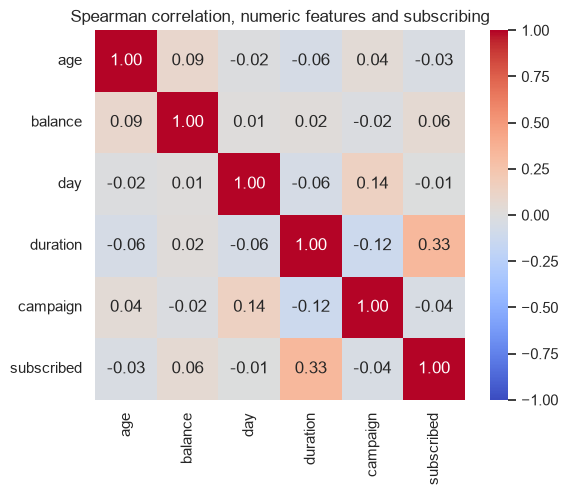

In [30]:
sns.heatmap(
    df[numeric_cols].assign(subscribed=subscribed).corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title("Spearman correlation, numeric features and subscribing")
plt.savefig(FIGURES_DIR / "spearman_correlation.png", bbox_inches="tight")
plt.show()

- No two numeric features are strongly correlated. The largest correlation is 0.14 (day and campaign), well below 0.5, Cohen's cutoff for a large correlation.
- Duration has the strongest correlation with subscribing (0.33), more than 5 times the next feature, balance (0.06). The other three are between -0.04 and -0.01.
- Age is close to 0 (-0.03) even though the age panel shows high rates at both ends. Correlation only measures a steady rise or fall, so it misses a pattern that is high at both ends and low in the middle.

In [31]:
cramers_v = pd.Series(
    {
        col: association(pd.crosstab(df[col], df[TARGET_COL]), method="cramer")
        for col in categorical_cols
    }
).sort_values(ascending=False)

cramers_v.round(2)

month        0.20
contact      0.09
job          0.06
marital      0.06
housing      0.05
education    0.05
loan         0.03
default      0.01
dtype: float64

Cramér's V measures how strongly each categorical column is linked to subscribing, from 0 (no link) to 1 (a perfect link). With a yes/no target, Cohen's cutoffs are 0.1 (small), 0.3 (medium), and 0.5 (large).

- Month has the strongest link (0.20), between small and medium. Its rates range from 3.2% in January to 61.3% in October, the widest spread of any categorical column.
- Every other column is below the 0.1 cutoff for a small link, from contact (0.09) down to `default` (0.01).

## Summary

The data has 40,000 rows with no missing values or duplicate rows. "Unknown" is kept as its own category in contact, education, and job.

Main findings:
- Only 7.2% of customers subscribed. A model that always predicts "no" scores 92.8% accuracy, already above the 81% target, so the models are compared on PR-AUC, recall, and precision.
- Duration is the strongest signal. Its correlation with subscribing (0.33) is more than 5 times that of any other numeric feature, and the median subscriber call is almost 4 times as long as the median non-subscriber call (629 vs. 164 seconds). Duration is known only after the call ends, so it cannot be used to decide whom to call.
- The rows are in time order, from May to the following June, and the subscription rate rises from 3.2% in the first fifth of the rows to 12.5% in the last. A model trained on these months could score differently on a later campaign.
- Month has the strongest link of the categorical columns (Cramér's V 0.20). The five busiest months make up about 84% of customers, and all five are below the overall 7.2%. October (61.3%) and March (48.4%) are far above it, with only 80 and 258 customers.
- Customers with an unknown contact type (31.9% of customers) subscribe at 3.9%, less than half the cellular rate of 9.0%. Almost all of them were called in the first two fifths of the rows, when the subscription rate was lowest.
- The subscription rate is highest at both ends of the age range, 13.4% under 25 and 18.0% for 60+. Students (15.6%) and retired customers (10.5%) have the highest job rates. Each of these groups is between 1.3% and 3.6% of customers, so the model has few examples of them.